# Limpeza e estruturação - variantes_simples
Ordem: limpeza base → codificação → correlação → split → imputação (treino) → escala (treino)

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from joblib import load, dump
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

In [22]:
caminho_arquivo = "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/data/variantes-final.plk"

df = load(caminho_arquivo)
print(df.shape)
display(df.head())

(1300, 16)


,gene,tipo_variante,ancestralidade,cadd_phred,cadd_raw,revel_score,gnomad_af,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,idade_inicio_sintomas,especie,genoma_referencia,classificacao_clinica,ataxia
0,PSEN1,frameshift,SAS,22.388,4.1531,0.5527,1.855986e-04,2.699,60.4,False,False,43.5,Homo_sapiens,GRCh38,VUS,nao especificada
1,SOD1,NaN,EUR,18.163,2.2878,0.4910,6.690338e-05,1.259,100.9,True,False,50.0,Homo_sapiens,GRCh38,VUS,nao especificada
2,HTT,nonsense,AMR,26.440,4.7984,0.7076,4.059568e-07,5.232,65.0,False,True,37.5,Homo_sapiens,GRCh38,Patogenica,cerebelar
3,HTT,missense,AFR,8.989,1.4305,0.1024,1.422524e-03,-1.480,80.0,False,False,51.8,Homo_sapiens,GRCh38,Benigna,esporadica
4,HTT,missense,AMR,18.539,3.5261,0.5452,1.214586e-03,-0.605,59.9,False,False,29.8,Homo_sapiens,GRCh38,VUS,nao especificada


## 1. Limpeza base 

In [23]:
# Remover duplicatas exatas
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicatas exatas removidas: {n0 - len(df)} (restam {len(df)} linhas)")

Duplicatas exatas removidas: 25 (restam 1275 linhas)


In [24]:
# Booleanas -> 0/1 (NaN continua como <NA>)
colunas_bool = df.select_dtypes(include=['bool', 'boolean']).columns.tolist()
df[colunas_bool] = df[colunas_bool].astype('Int64')
print("Booleanas:", colunas_bool)

Booleanas: ['em_dominio_funcional', 'historico_familiar']


In [25]:
# Remover colunas constantes 
ALVO_CLF = 'ataxia'
ALVO_REG = 'idade_inicio_sintomas'

colunas_constantes = [col for col in df.columns
                      if df[col].nunique(dropna=True) <= 1 and col != ALVO_CLF]
print("Removendo colunas constantes:", colunas_constantes)
df_base = df.drop(columns=colunas_constantes)

Removendo colunas constantes: ['especie', 'genoma_referencia']


In [26]:
# Faltantes por coluna (%)
faltantes = (df_base.isna().mean() * 100).round(1)
print(faltantes[faltantes > 0].sort_values(ascending=False))

historico_familiar       6.7
ancestralidade           6.2
em_dominio_funcional     4.5
cadd_phred               4.5
idade_inicio_sintomas    4.4
conservacao_phylop       4.1
gnomad_af                2.9
tipo_variante            2.8
profundidade_leitura     2.6
dtype: float64


In [27]:
# Eliminar faltantes de "tipo_variante" antes de transformar para numerico
n_antes_tv = len(df_base)
df_base = df_base.dropna(subset=['tipo_variante']).reset_index(drop=True)
print(f"Linhas removidas sem tipo_variante: {n_antes_tv - len(df_base)} (restam {len(df_base)} linhas)")

Linhas removidas sem tipo_variante: 36 (restam 1239 linhas)


In [28]:
# gnomad_af: os zeros são REAIS (variante nunca observada)
# log10 reduz a assimetria e mantém o zero como o menor valor.
print(f"Zeros em gnomad_af: {(df_base['gnomad_af'] == 0).mean():.1%}")
df_base['gnomad_af_log'] = np.log10(df_base['gnomad_af'] + 1e-8)
df_base = df_base.drop(columns=['gnomad_af'])

Zeros em gnomad_af: 23.4%


## 2. Categóricas -> numéricas

In [29]:
# 1. Definir as colunas categóricas do seu dataset
colunas_categoricas = ['tipo_variante', 'ancestralidade', 'gene', 'classificacao_clinica']

# 2. Criar o Pipeline para tratar os nulos e fazer a codificação
pipeline_categorico = Pipeline(
    steps=[
        # Preenche os nulos com a categoria 'Desconhecido'
        (
            'imputer',
            SimpleImputer(strategy='constant', fill_value='Desconhecido'),
        ),
        # Aplica o One-Hot Encoding
        ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore')),
    ]
)

# 3. Aplicar o Pipeline às colunas desejadas do DataFrame (assumindo que se chama df)
preprocessor = ColumnTransformer(
    transformers=[('cat', pipeline_categorico, colunas_categoricas)],
    remainder='passthrough',  # Mantém intactas as restantes colunas (como ID ou variáveis numéricas)
    verbose_feature_names_out=False,
)

preprocessor.set_output(transform='pandas')  

# 4. Processar o DataFrame
dados_transformados = preprocessor.fit_transform(df_base)

#5. Atualizar o df_base transformado em DataFrame com os novos nomes de colunas
df_base = pd.DataFrame(
    dados_transformados,
    columns=preprocessor.get_feature_names_out(),
    index=df_base.index,
)

# Visualizar
print(df_base.head())

# Salva o preprocessor ajustado (imputer + one-hot) para reuso futuro
dump(preprocessor, "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/preprocessor_categorico.pkl")

   tipo_variante_frameshift  tipo_variante_missense  tipo_variante_nonsense  \
0                       1.0                     0.0                     0.0   
1                       0.0                     0.0                     1.0   
2                       0.0                     1.0                     0.0   
3                       0.0                     1.0                     0.0   
4                       0.0                     1.0                     0.0   

   ancestralidade_AFR  ancestralidade_AMR  ancestralidade_Desconhecido  \
0                 0.0                 0.0                          0.0   
1                 0.0                 1.0                          0.0   
2                 1.0                 0.0                          0.0   
3                 0.0                 1.0                          0.0   
4                 0.0                 1.0                          0.0   

   ancestralidade_EAS  ancestralidade_EUR  ancestralidade_SAS  gene_HTT  ...  \


['/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/preprocessor_categorico.pkl']

In [30]:
#Target (categorico -> numerico) - LabelEncoder
label_encoder = LabelEncoder()

# Transforma a coluna 'ataxia' em valores numericos (0,1,2)
df_base['ataxia'] = label_encoder.fit_transform(df_base['ataxia'])

# Exibir mapeamento gerado
mapeamento = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("---Mapeamento de Classes do Target ---")
for classe, codigo in mapeamento.items():
    print(f"Rótulo: '{classe}' -> Código: {codigo}")

# Exemplo de saida
print("\nPrimeiros 5 valores codificados (ataxia):", df_base['ataxia'].head().tolist())

dump(label_encoder, "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/label_encoder_ataxia.pkl")


---Mapeamento de Classes do Target ---
Rótulo: 'cerebelar' -> Código: 0
Rótulo: 'esporadica' -> Código: 1
Rótulo: 'nao especificada' -> Código: 2

Primeiros 5 valores codificados (ataxia): [2, 0, 1, 2, 2]


['/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/label_encoder_ataxia.pkl']

## Salvar em CSV um dicionário da conversão categórico -> numérico para análise depois

In [31]:
# Extrai as categorias aprendidas pelo OneHotEncoder, por coluna original
onehot = preprocessor.named_transformers_['cat'].named_steps['onehot']

linhas = []
for coluna, categorias in zip(colunas_categoricas, onehot.categories_):
    for categoria in categorias:
        linhas.append({
            'coluna_original': coluna,
            'categoria': categoria,
        })

df_categorias_onehot = pd.DataFrame(linhas)
df_categorias_onehot.to_csv("/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/categorias_onehot.csv", index=False)

print(df_categorias_onehot)

          coluna_original     categoria
0           tipo_variante    frameshift
1           tipo_variante      missense
2           tipo_variante      nonsense
3          ancestralidade           AFR
4          ancestralidade           AMR
5          ancestralidade  Desconhecido
6          ancestralidade           EAS
7          ancestralidade           EUR
8          ancestralidade           SAS
9                    gene           HTT
10                   gene         LRRK2
11                   gene         PSEN1
12                   gene          SOD1
13  classificacao_clinica       Benigna
14  classificacao_clinica    Patogenica
15  classificacao_clinica           VUS


In [32]:
df_mapeamento_target = pd.DataFrame(
    list(mapeamento.items()), columns=['classe', 'codigo']
)
df_mapeamento_target.to_csv("/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/mapeamento_ataxia.csv", index=False)

## 3. Correlação entre as colunas
Usa só as features (sem os alvos), então não vaza informação do alvo para o teste.

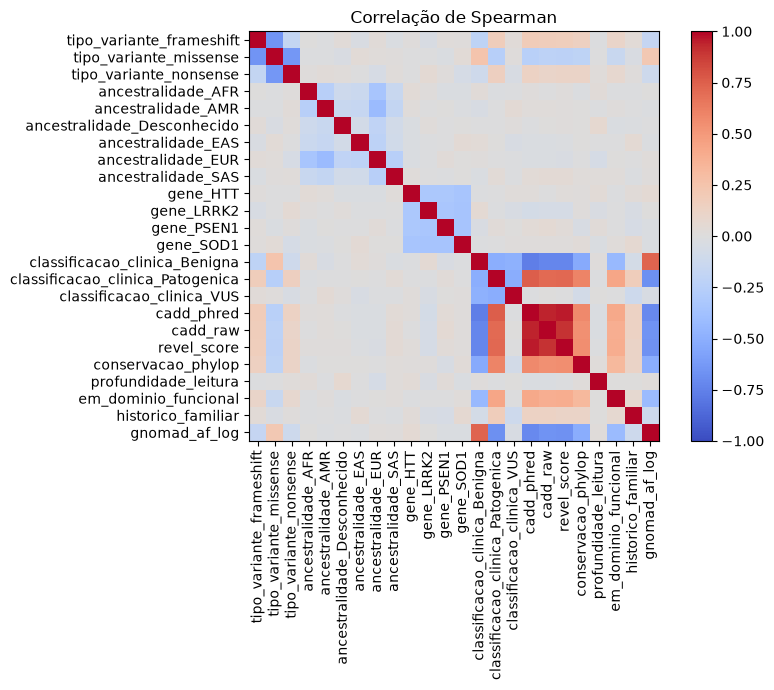

In [33]:
# Matriz de correlação de Spearman (o pandas ignora os NaN par a par, então usa os valores reais)
colunas_features = [c for c in df_base.columns if c not in [ALVO_CLF, ALVO_REG]]
corr = df_base[colunas_features].astype('float64').corr(method='spearman')

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.title('Correlação de Spearman')
plt.tight_layout()
plt.show()

In [34]:
# Pares muito correlacionados
LIMIAR = 0.80
abs_corr = corr.abs()
cols = list(abs_corr.columns)
pares = [(a, b, abs_corr.loc[a, b]) for i, a in enumerate(cols) for b in cols[i + 1:]
         if abs_corr.loc[a, b] >= LIMIAR]
pares = sorted(pares, key=lambda t: -t[2])

print(f"Pares com |rho| >= {LIMIAR}:")
for a, b, r in pares:
    print(f"  {a} x {b}: {r:.2f}")

Pares com |rho| >= 0.8:
  cadd_phred x revel_score: 0.96
  cadd_phred x cadd_raw: 0.94
  cadd_raw x revel_score: 0.90


In [35]:
# Remover as colunas correlacionadas: em cada par, sai a coluna que NÃO está em MANTER
# (se nenhuma está, sai a mais correlacionada com as demais)
MANTER = ['cadd_phred']
media = abs_corr.mean()
colunas_remover = set()
for a, b, r in pares:
    if a in colunas_remover or b in colunas_remover:
        continue
    if a in MANTER:
        colunas_remover.add(b)
    elif b in MANTER:
        colunas_remover.add(a)
    else:
        colunas_remover.add(a if media[a] >= media[b] else b)
colunas_remover = sorted(colunas_remover)
print("Removendo por correlação:", colunas_remover)

df_base = df_base.drop(columns=colunas_remover)
colunas_bool = [c for c in colunas_bool if c in df_base.columns]
print(df_base.shape)

Removendo por correlação: ['cadd_raw', 'revel_score']
(1239, 24)


In [36]:
# Eliminar linhas com faltantes (colunas correlacionadas já foram removidas)
colunas_dropna = ['gnomad_af_log', 'conservacao_phylop',
                  'em_dominio_funcional', 'profundidade_leitura', 'idade_inicio_sintomas']

n1 = len(df_base)
df_base = df_base.dropna(subset=colunas_dropna)
print(f"Linhas removidas por faltantes: {n1 - len(df_base)} (restam {len(df_base)})")

Linhas removidas por faltantes: 216 (restam 1023)


In [37]:
# Checagem e salva a base limpa (já sem as colunas correlacionadas, antes do split)
print(df_base.dtypes.astype(str).value_counts())
print(df_base.select_dtypes(include=['object', 'category']).columns.tolist())  # deve ser []
print(df_base.shape)

dump(df_base, "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/variantes-final-limpo-v1.pkl")

float64    21
Int64       2
int64       1
Name: count, dtype: int64
[]
(1023, 24)


['/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/variantes-final-limpo-v1.pkl']

In [42]:
dump(df_base, "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/variantes-final-limpo-v1.pkl")
df_base.to_csv("/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/variantes-final-limpo-v1.csv", index=False)

In [43]:
display(df_base.head())

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,classificacao_clinica_Patogenica,classificacao_clinica_VUS,cadd_phred,conservacao_phylop,profundidade_leitura,em_dominio_funcional,historico_familiar,idade_inicio_sintomas,ataxia,gnomad_af_log
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,22.388,2.699,60.4,0,0,43.5,2,-3.731402
1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,26.440,5.232,65.0,0,1,37.5,0,-6.380952
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,8.989,-1.480,80.0,0,0,51.8,1,-2.846937
3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,18.539,-0.605,59.9,0,0,29.8,2,-2.915568
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,8.904,0.245,75.5,0,1,52.1,2,-3.330104


## 4. CONFERIR BALANCEAMENTO

In [40]:
contagem = df_base['ataxia'].value_counts().sort_index()
percentual = df_base['ataxia'].value_counts(normalize=True).sort_index()*100

df_dist = pd.DataFrame({'contagem': contagem, 'percentual': percentual.round(1)})

mapeamento_inverso = {v: k for k, v in mapeamento.items()}
df_dist.index = df_dist.index.map(mapeamento_inverso)

print (f"--- Balanceamento de 'ataxia' após limpeza (n={len(df_base)}) ---")
print(df_dist)

--- Balanceamento de 'ataxia' após limpeza (n=1023) ---
                  contagem  percentual
ataxia                                
cerebelar              342        33.4
esporadica             328        32.1
nao especificada       353        34.5


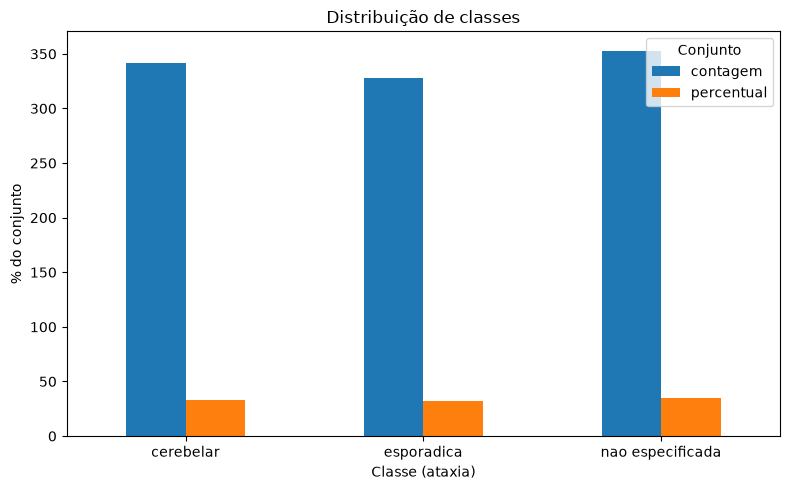

                  contagem  percentual
ataxia                                
cerebelar              342        33.4
esporadica             328        32.1
nao especificada       353        34.5


In [41]:
# Gráfico de barras agrupadas
ax = df_dist.plot(kind='bar', figsize=(8, 5), rot=0)
ax.set_xlabel('Classe (ataxia)')
ax.set_ylabel('% do conjunto')
ax.set_title('Distribuição de classes')
ax.legend(title='Conjunto')

plt.tight_layout()
plt.show()

print(df_dist.round(1))